In [ ]:
from __future__ import annotations

import csv
import statistics
import sys
from dataclasses import dataclass
from pathlib import Path
import pandas as pd

MISSING = {'', 'na', 'n/a', 'null', 'none', 'nan', '?'}
Row = dict[str, str | None]
Data = dict[str, list[str]]

import pandas as pd

In [ ]:
names = ['Ali','Sara','Bilal']
amounts = [12000, 420000, 3000]
for n, a in zip(names, sorted(amounts)):
  print(n, a)

Ali 3000
Sara 12000
Bilal 420000


In [ ]:
df = pd.DataFrame({'name': names, 'amount': amounts})
df.sort_values('amount')

,name,amount
2,Bilal,3000
0,Ali,12000
1,Sara,420000


In [ ]:
%%writefile sales.csv
order_id,order_date,customer_id,region,category,product,quantity,unit_price,discount
5001,2026-03-24,K102,Lahore,Electronics,Earbuds Pro,2,4860,0
5001,2026-03-24,K102,Lahore,Fashion,Sneakers,1,7000,0.1
5001,2026-03-24,K102,Lahore,Home,Cookware Set,1,8000,0.05
5001,2026-03-24,K102,Lahore,Fashion,Cap,1,900,0
5002,2026-05-22,K016,Peshawar,Electronics,Smart Lamp,1,2800,0.1
5002,2026-05-22,K016,Peshawar,Grocery,Biscuits,5,120,0
5002,2026-05-22,K016,Peshawar,Grocery,Biscuits,1,120,0.1
5003,2026-08-08,K075,Lahore,Home,Blender,1,6500,0.1
5003,2026-08-08,K075,Lahore,Fashion,Sneakers,3,7000,0
5004,2026-01-27,K096,Lahore,Grocery,Rice 5kg,1,1800,0.1
5005,2026-01-16,K128,Lahore,Grocery,Rice 5kg,3,1800,0.05
5005,2026-01-16,K128,Lahore,Grocery,Rice 5kg,5,1800,
5005,2026-01-16,K128,Lahore,Home,Bedsheet,1,2200,
5005,2026-01-16,K128,Lahore,Electronics,Earbuds Pro,1,4500,0.1
5006,2026-05-07,K115,Islamabad,Grocery,Cooking Oil,1,1200,0
5006,2026-05-07,K115,Islamabad,Grocery,Rice 5kg,2,1800,0
5007,2026-02-08,K108,Peshawar,Grocery,Biscuits,1,120,0.1
5008,2026-05-27,K088,Islamabad,Fashion,Sneakers,2,7000,0.1
5008,2026-05-27,K088,Islamabad,Grocery,Tea Pack,1,650,0
5008,2026-05-27,K088,Islamabad,Grocery,Biscuits,5,120,0
5008,2026-05-27,K088,Islamabad,Electronics,Power Bank,3,3200,0
5009,2026-06-15,K073,Peshawar,Home,Bedsheet,3,2200,0
5009,2026-06-15,K073,Peshawar,Electronics,Earbuds Pro,2,5400,0
5009,2026-06-15,K073,Peshawar,Electronics,Smart Lamp,1,2800,0.05
5009,2026-06-15,K073,Peshawar,Electronics,Power Bank,1,3200,0
5010,2026-07-09,K102,Lahore,Grocery,Biscuits,5,120,0
5010,2026-07-09,K102,Lahore,Home,Blender,2,6500,0.1
5011,2026-03-13,K111,Lahore,Home,Bedsheet,2,2200,0
5011,2026-03-13,K111,Lahore,Grocery,Cooking Oil,5,1200,0
5011,2026-03-13,K111,Lahore,Electronics,Smart Lamp,1,2800,0
5012,2026-03-01,K004,Lahore,Grocery,Tea Pack,2,650,0
5012,2026-03-01,K004,Lahore,Home,Bedsheet,1,2200,0.05
5013,2026-05-17,K145,Islamabad,Grocery,Biscuits,1,120,0.05
5013,2026-05-17,K145,Islamabad,Grocery,Biscuits,5,120,0.05
5014,2026-04-13,K027,Peshawar,Grocery,Cooking Oil,1,1200,0
5014,2026-04-13,K027,Peshawar,Electronics,Power Bank,1,3200,0.05
5015,2026-02-11,K088,Karachi,Electronics,Earbuds Pro,1,4680,0.1
5015,2026-02-11,K088,Karachi,Electronics,Smart Lamp,1,2800,0
5015,2026-02-11,K088,Karachi,Grocery,Cooking Oil,1,1200,0
5016,2026-06-07,K039,Peshawar,Electronics,Smart Lamp,1,2800,0.1
5016,2026-06-07,K039,Peshawar,Home,Bedsheet,1,2200,0
5016,2026-06-07,K039,Peshawar,Grocery,Tea Pack,5,650,0.05
5016,2026-06-07,K039,Peshawar,Fashion,Cap,1,900,0
5017,2026-01-27,K068,Islamabad,Grocery,Tea Pack,2,650,0.1
5017,2026-01-27,K068,Islamabad,Electronics,Earbuds Pro,2,4500,
5018,2026-02-07,K136,Karachi,Grocery,Biscuits,1,120,0
5018,2026-02-07,K136,Karachi,Grocery,Rice 5kg,2,1800,
5019,2026-07-17,K137,Lahore,Grocery,Tea Pack,3,650,0
5019,2026-07-17,K137,Lahore,Grocery,Cooking Oil,2,1200,0
5019,2026-07-17,K137,Lahore,Grocery,Tea Pack,2,650,0
5020,2026-05-13,K092,Peshawar,Electronics,Earbuds Pro,1,5220,0
5020,2026-05-13,K092,Peshawar,Grocery,Rice 5kg,2,1800,0.1
5020,2026-05-13,K092,Peshawar,Grocery,Biscuits,5,120,0
5020,2026-05-13,K092,Peshawar,Grocery,Biscuits,3,120,0
5021,2026-02-26,K059,Karachi,Home,Blender,1,6500,0.05
5021,2026-02-26,K059,Karachi,Grocery,Cooking Oil,1,1200,0.05
5022,2026-06-17,K022,Islamabad,Electronics,Smart Lamp,2,2800,0
5022,2026-06-17,K022,Islamabad,Fashion,Cap,1,900,0.05
5022,2026-06-17,K022,Islamabad,Grocery,Tea Pack,3,650,0
5022,2026-06-17,K022,Islamabad,Grocery,Tea Pack,5,650,0.05
5023,2026-04-13,K041,Karachi,Grocery,Biscuits,1,120,0
5024,2026-06-01,K038,Peshawar,Grocery,Tea Pack,5,650,
5024,2026-06-01,K038,Peshawar,Electronics,Smart Lamp,2,2800,0
5024,2026-06-01,K038,Peshawar,Electronics,Earbuds Pro,3,5400,0
5025,2026-05-15,K112,Lahore,Grocery,Tea Pack,2,650,0
5026,2026-03-06,K075,Lahore,Home,Cookware Set,2,8000,0
5026,2026-03-06,K075,Lahore,Home,Bedsheet,2,2200,0
5026,2026-03-06,K075,Lahore,Electronics,Earbuds Pro,3,4860,0
5027,2026-04-28,K129,Peshawar,Grocery,Rice 5kg,1,1800,0.05
5028,2026-07-18,K002,Lahore,Home,Cookware Set,2,8000,0.1
5029,2026-07-05,K143,Karachi,Fashion,Sneakers,2,7000,0.1
5030,2026-05-23,K028,Peshawar,Electronics,Power Bank,1,3200,0
5030,2026-05-23,K028,Peshawar,Electronics,Earbuds Pro,1,5220,0.1
5030,2026-05-23,K028,Peshawar,Grocery,Rice 5kg,1,1800,
5031,2026-04-24,K130,Islamabad,Grocery,Rice 5kg,3,1800,0.05
5031,2026-04-24,K130,Islamabad,Grocery,Rice 5kg,5,1800,0.1
5031,2026-04-24,K130,Islamabad,Grocery,Biscuits,3,120,0.1
5032,2026-02-21,K036,Peshawar,Electronics,Power Bank,2,3200,0
5032,2026-02-21,K036,Peshawar,Electronics,Earbuds Pro,1,4680,0.05
5033,2026-01-19,K078,Lahore,Grocery,Biscuits,2,120,0
5034,2026-02-06,K036,Islamabad,Home,Blender,1,6500,0.05
5034,2026-02-06,K036,Islamabad,Grocery,Biscuits,2,120,0
5035,2026-02-11,K132,Peshawar,Fashion,Kurta,1,3500,0
5035,2026-02-11,K132,Peshawar,Fashion,Kurta,3,3500,0
5036,2026-01-05,K142,Islamabad,Fashion,Cap,1,900,0.05
5036,2026-01-05,K142,Islamabad,Fashion,Kurta,2,3500,
5037,2026-05-12,K029,Karachi,Grocery,Biscuits,1,120,0
5038,2026-03-09,K011,Islamabad,Home,Bedsheet,1,2200,0.05
5039,2026-08-06,K104,Islamabad,Grocery,Rice 5kg,5,1800,0
5040,2026-01-23,K015,Islamabad,Electronics,Smart Lamp,1,2800,0
5040,2026-01-23,K015,Islamabad,Grocery,Biscuits,1,120,0
5040,2026-01-23,K015,Islamabad,Electronics,Earbuds Pro,1,4500,0
5040,2026-01-23,K015,Islamabad,Home,Cookware Set,1,8000,0.05
5041,2026-01-03,K142,Islamabad,Grocery,Biscuits,3,120,0.1
5041,2026-01-03,K142,Islamabad,Electronics,Power Bank,2,3200,0
5042,2026-01-29,K068,Lahore,Electronics,Smart Lamp,1,2800,0
5043,2026-05-16,K075,Lahore,Grocery,Rice 5kg,2,1800,0
5043,2026-05-16,K075,Lahore,Fashion,Sneakers,1,7000,0
5044,2026-01-10,K005,Karachi,Grocery,Rice 5kg,2,1800,0.1
5044,2026-01-10,K005,Karachi,Grocery,Rice 5kg,5,1800,0
5044,2026-02-30,K005,Karachi,Grocery,Cooking Oil,5,1200,0.05
5044,2026-01-10,K005,Karachi,Grocery,Rice 5kg,5,1800,0.1
5045,2026-03-20,K059,Lahore,Home,Blender,3,6500,0
5045,2026-03-20,K059,Lahore,Fashion,Cap,1,900,0
5046,2026-08-03,K004,Lahore,Grocery,Cooking Oil,3,1200,0.05
5047,2026-02-11,K022,Karachi,Grocery,Tea Pack,3,650,0.1
5047,2026-02-11,K022,Karachi,Home,Cookware Set,1,8000,0
5047,2026-02-11,K022,Karachi,Grocery,Rice 5kg,2,1800,0
5047,2026-02-11,K022,Karachi,Fashion,Cap,1,900,0
5048,2026-03-26,K063,Islamabad,Grocery,Biscuits,3,120,0
5049,2026-04-02,K001,Lahore,Fashion,Sneakers,2,7000,0
5049,2026-04-02,K001,,Grocery,Rice 5kg,2,1800,0
5050,2026-05-10,K024,Karachi,Grocery,Tea Pack,2,650,0.05
5050,2026-05-10,K024,Karachi,Grocery,Cooking Oil,5,1200,
5051,2026-03-18,K060,Islamabad,Grocery,Cooking Oil,2,1200,0.1
5052,2026-04-10,K127,Islamabad,Home,Bedsheet,2,2200,
5053,2026-01-12,K130,Peshawar,Grocery,Biscuits,1,120,0.1
5054,2026-07-24,K022,Lahore,Electronics,Power Bank,3,3200,
5055,2026-01-27,K116,Peshawar,Electronics,Earbuds Pro,1,4500,0.1
5055,2026-01-27,K116,Peshawar,Grocery,Cooking Oil,5,1200,0
5055,2026-01-27,K116,Peshawar,Electronics,Earbuds Pro,1,4500,0.1
5056,2026-05-18,K135,Karachi,Grocery,Tea Pack,5,650,0
5057,2026-07-27,K068,Karachi,Grocery,Tea Pack,2,650,0
5058,2026-07-09,K127,Peshawar,Electronics,Smart Lamp,3,2800,0
5058,2026-07-09,K127,Peshawar,Grocery,Tea Pack,2,650,0
5059,2026-06-03,K085,Lahore,Grocery,Cooking Oil,3,1200,0.1
5059,2026-06-03,K085,Lahore,Grocery,Rice 5kg,1,1800,0.05
5060,2026-01-16,K069,Peshawar,Electronics,Power Bank,1,3200,0.05
5060,2026-01-16,K069,Peshawar,Home,Bedsheet,2,2200,0
5060,2026-01-16,K069,Peshawar,Grocery,Rice 5kg,5,1800,0
5060,2026-01-16,K069,Peshawar,Grocery,Biscuits,2,120,0
5061,2026-01-22,K005,Peshawar,Fashion,Cap,2,900,0.05
5061,2026-01-22,K005,Peshawar,Grocery,Biscuits,5,120,0
5062,2026-02-23,K149,Karachi,Electronics,Smart Lamp,2,2800,0
5063,2026-04-03,K131,Lahore,Grocery,Biscuits,3,120,0
5063,2026-04-03,K131,Lahore,Grocery,Rice 5kg,5,1800,0.05
5064,2026-01-07,K001,Lahore,Grocery,Cooking Oil,5,1200,0
5064,2026-01-07,K001,Lahore,Grocery,Cooking Oil,5,1200,0
5065,2026-04-07,K031,Islamabad,Electronics,Earbuds Pro,1,5040,0.05
5065,2026-04-07,K031,Islamabad,Electronics,Smart Lamp,1,2800,0
5066,2026-07-09,K065,Islamabad,Electronics,Power Bank,2,3200,0.1
5066,2026-07-09,K065,Islamabad,Electronics,Smart Lamp,2,2800,0
5067,2026-08-07,K072,Karachi,Electronics,Power Bank,3,3200,0
5068,2026-06-12,K064,Lahore,Fashion,Sneakers,1,7000,0
5068,2026-06-12,K064,Lahore,Grocery,Tea Pack,5,650,0
5069,2026-07-27,K142,Peshawar,Home,Cookware Set,1,8000,0
5069,2026-07-27,K142,Peshawar,Grocery,Biscuits,5,120,0.05
5069,2026-07-27,K142,Peshawar,Grocery,Cooking Oil,2,1200,0
5070,2026-05-05,K141,Karachi,Home,Blender,2,6500,0
5071,2026-03-14,K066,Islamabad,Grocery,Tea Pack,3,650,0.05
5071,2026-03-14,K066,Islamabad,Grocery,Cooking Oil,3,1200,0.05
5071,2026-03-14,K066,Islamabad,Grocery,Rice 5kg,5,1800,0
5071,2026-03-14,K066,Islamabad,Home,Blender,1,6500,0
5072,2026-02-23,K141,Peshawar,Grocery,Rice 5kg,3,1800,0.05
5073,2026-04-20,K141,Lahore,Home,Cookware Set,1,8000,0
5074,2026-05-23,K082,Karachi,Fashion,Sneakers,2,7000,0
5075,2026-01-06,K099,Peshawar,Grocery,Tea Pack,2,650,0.05
5075,2026-01-06,K099,Peshawar,Home,Cookware Set,1,8000,0.05
5076,2026-03-13,K033,Islamabad,Grocery,Rice 5kg,2,1800,0
5076,2026-03-13,K033,Islamabad,Home,Bedsheet,1,2200,0.05
5076,2026-03-13,K033,Islamabad,Fashion,Cap,2,900,0.05
5076,2026-03-13,K033,Islamabad,Grocery,Biscuits,1,120,0
5077,2026-01-09,K122,Peshawar,Grocery,Rice 5kg,1,1800,0.05
5077,2026-01-09,K122,Peshawar,Grocery,Biscuits,5,120,0.05
5077,2026-01-09,K122,Peshawar,Home,Cookware Set,1,8000,0
5078,2026-02-09,K134,Lahore,Electronics,Power Bank,3,3200,
5078,2026-02-09,K134,Lahore,Electronics,Earbuds Pro,1,4680,0
5078,2026-02-09,K134,Lahore,Grocery,Tea Pack,2,650,0.1
5078,2026-02-09,K134,Lahore,Grocery,Biscuits,3,120,0
5079,2026-06-10,K136,Islamabad,Fashion,Sneakers,1,7000,0
5079,2026-06-10,K136,Islamabad,Electronics,Smart Lamp,2,2800,0.1
5079,2026-06-10,K136,Islamabad,Electronics,Smart Lamp,1,2800,0
5079,2026-06-10,K136,Islamabad,Grocery,Tea Pack,1,650,
5080,2026-05-18,K118,Islamabad,Grocery,Biscuits,2,120,0.05
5080,2026-05-18,K118,Islamabad,Grocery,Rice 5kg,2,1800,0
5081,2026-04-16,K015,Islamabad,Home,Blender,3,6500,0.05
5082,2026-01-21,K059,Islamabad,Fashion,Cap,1,900,0
5082,2026-01-21,K059,Islamabad,Grocery,Rice 5kg,3,1800,0.05
5082,2026-01-21,K059,Islamabad,Fashion,Kurta,2,3500,0
5082,2026-01-21,K059,Islamabad,Electronics,Earbuds Pro,1,4500,0.1
5083,2026-01-18,K127,Lahore,Home,Bedsheet,1,2200,0
5084,2026-04-30,K068,Lahore,Electronics,Smart Lamp,2,2800,0.05
5084,2026-04-30,K068,Lahore,Grocery,Cooking Oil,2,1200,0.05
5085,2026-04-17,K038,Karachi,Electronics,Earbuds Pro,1,5040,0.1
5085,2026-04-17,K038,Karachi,Electronics,Smart Lamp,1,2800,0
5086,2026-02-17,K116,Peshawar,Grocery,Biscuits,1,120,0
5086,2026-02-17,K116,Peshawar,Grocery,Biscuits,3,120,0
5086,2026-02-17,K116,Peshawar,Home,Blender,2,6500,0.05
5086,2026-02-17,K116,Peshawar,Electronics,Earbuds Pro,3,4680,0.05
5087,2026-08-03,K085,Islamabad,Home,Cookware Set,1,8000,0
5087,2026-08-03,K085,Islamabad,Fashion,Kurta,1,3500,0.05
5088,2026-08-15,K144,Karachi,Fashion,Cap,1,900,0.05
5089,2026-01-23,K122,Karachi,Fashion,Sneakers,2,7000,0
5090,2026-03-24,K122,Islamabad,Grocery,Cooking Oil,2,1200,0.05
5091,2026-01-11,K009,,Electronics,Earbuds Pro,1,4500,0
5091,2026-01-11,K009,Peshawar,Home,Blender,1,6500,0.1
5092,2026-03-28,K070,Islamabad,Grocery,Biscuits,1,120,0
5092,2026-03-28,K070,Islamabad,Grocery,Tea Pack,3,650,0
5093,2026-03-18,K017,Karachi,Grocery,Tea Pack,1,650,0.05
5094,2026-07-03,K099,Peshawar,Grocery,Biscuits,5,120,0
5094,2026-07-03,K099,Peshawar,Grocery,Biscuits,2,120,0
5095,2026-07-25,K039,Islamabad,Home,Bedsheet,1,2200,
5095,2026-07-25,K039,Islamabad,Fashion,Sneakers,2,7000,0
5095,2026-07-25,K039,Islamabad,Grocery,Rice 5kg,5,1800,0
5096,2026-03-05,K017,Peshawar,Electronics,Earbuds Pro,2,4860,0.1
5096,2026-03-05,K017,Peshawar,Fashion,Kurta,2,3500,0
5096,2026-03-05,K017,Peshawar,Grocery,Biscuits,3,120,0.1
5096,2026-03-05,K017,Peshawar,Electronics,Power Bank,1,3200,0.05
5097,2026-05-08,K045,Peshawar,Electronics,Smart Lamp,2,2800,0.1
5098,2026-06-22,K138,Lahore,Grocery,Tea Pack,3,650,0
5098,2026-06-22,K138,Lahore,Home,Blender,1,6500,0
5098,2026-06-22,K138,Lahore,Electronics,Smart Lamp,1,2800,
5098,2026-06-22,K138,Lahore,Fashion,Sneakers,1,7000,0
5099,2026-03-02,K073,Lahore,Home,Blender,1,6500,0.05
5099,2026-03-02,K073,Lahore,Home,Cookware Set,1,8000,0.1
5099,2026-03-02,K073,Lahore,Grocery,Rice 5kg,1,1800,0.05
5100,2026-01-10,K002,Karachi,Grocery,Biscuits,2,120,0.05
5100,2026-01-10,K002,Karachi,Grocery,Biscuits,1,120,0
5101,2026-03-01,K013,Karachi,Grocery,Cooking Oil,2,1200,0
5102,2026-04-06,K115,Lahore,Home,Bedsheet,3,2200,0
5102,2026-04-06,K115,Lahore,Electronics,Power Bank,2,3200,0.1
5102,2026-04-06,K115,Lahore,Fashion,Sneakers,1,7000,0
5103,2026-03-29,K012,Lahore,Grocery,Biscuits,1,120,0.1
5104,2026-07-07,K003,Lahore,Fashion,Cap,1,900,0
5104,2026-07-07,K003,Lahore,Grocery,Cooking Oil,1,1200,0
5105,2026-01-09,K141,Peshawar,Electronics,Earbuds Pro,1,4500,0.05
5105,2026-01-09,K141,Peshawar,Grocery,Cooking Oil,2,1200,0.1
5106,2026-01-24,K102,Lahore,Home,Cookware Set,1,8000,0
5106,2026-01-24,K102,Lahore,Fashion,Cap,1,900,0
5106,2026-01-24,K102,Lahore,Grocery,Tea Pack,3,650,0.05
5106,2026-01-24,K102,Lahore,Fashion,Cap,1,900,0
5107,2026-04-11,K053,Peshawar,Fashion,Cap,1,900,0.05
5108,2026-01-30,K104,Karachi,Grocery,Biscuits,5,120,0
5108,2026-01-30,K104,Karachi,Electronics,Power Bank,1,3200,0.1
5108,2026-01-30,K104,Karachi,Electronics,Power Bank,2,3200,0
5109,2026-05-27,K130,Islamabad,Home,Blender,1,6500,0
5110,2026-05-14,K018,Lahore,Fashion,Cap,1,900,0
5111,2026-02-02,K124,Karachi,Electronics,Earbuds Pro,3,4680,0.05
5111,2026-02-02,K124,Karachi,Electronics,Earbuds Pro,3,4680,0.1
5112,2026-06-26,K057,Lahore,Fashion,Kurta,1,3500,0.05
5112,2026-06-26,K057,Lahore,Electronics,Smart Lamp,1,2800,0
5112,2026-06-26,K057,Lahore,Fashion,Kurta,2,3500,0
5113,2026-04-09,K032,Islamabad,Home,Cookware Set,3,8000,0
5114,2026-01-11,K083,Karachi,Fashion,Sneakers,2,7000,0.1
5115,2026-08-06,K108,Islamabad,Grocery,Cooking Oil,5,1200,0.05
5115,2026-08-06,K108,Islamabad,Grocery,Cooking Oil,5,1200,0.1
5116,2026-04-23,K006,Lahore,Grocery,Cooking Oil,5,1200,0.05
5117,2026-03-02,K118,Peshawar,Grocery,Tea Pack,5,650,0
5118,2026-01-18,K092,Lahore,Fashion,Kurta,2,3500,0.1
5118,2026-01-18,K092,Lahore,Grocery,Rice 5kg,1,1800,0
5119,15/13/2026,K022,Lahore,Home,Cookware Set,3,8000,0.1
5119,2026-06-12,K022,Lahore,Electronics,Smart Lamp,2,2800,0.05
5119,2026-06-12,K022,Lahore,Grocery,Cooking Oil,2,1200,0
5119,2026-06-12,K022,Lahore,Grocery,Tea Pack,1,650,0
5120,2026-02-03,K074,Peshawar,Grocery,Cooking Oil,2,1200,0
5121,2026-08-02,K065,Islamabad,Fashion,Sneakers,2,7000,0
5122,2026-07-28,K037,Peshawar,Grocery,Rice 5kg,5,1800,0
5122,2026-07-28,K037,Peshawar,Grocery,Cooking Oil,2,1200,0
5123,2026-04-06,K051,Karachi,Fashion,Cap,3,900,0
5124,2026-06-23,K097,Islamabad,Grocery,Tea Pack,3,650,0
5125,2026-07-16,K093,Karachi,Grocery,Rice 5kg,1,1800,0
5125,2026-07-16,K093,Karachi,Grocery,Biscuits,5,120,0
5126,2026-03-09,K095,Peshawar,Electronics,Smart Lamp,1,2800,0
5126,2026-03-09,K095,Peshawar,Fashion,Cap,1,900,0.1
5126,2026-03-09,K095,Peshawar,Grocery,Tea Pack,1,650,0
5127,2026-07-29,K080,Islamabad,Grocery,Biscuits,3,120,0
5127,2026-07-29,K080,Islamabad,Grocery,Tea Pack,2,650,0
5127,2026-07-29,K080,Islamabad,Fashion,Kurta,3,3500,0.05
5127,2026-07-29,K080,Islamabad,Grocery,Rice 5kg,3,1800,0
5128,2026-02-03,K059,Peshawar,Grocery,Cooking Oil,1,1200,0
5128,2026-02-03,K059,,Electronics,Earbuds Pro,1,4680,0
5128,2026-02-03,K059,Peshawar,Electronics,Power Bank,1,3200,0.1
5129,2026-02-27,K150,Peshawar,Grocery,Cooking Oil,2,1200,0
5129,2026-02-27,K150,Peshawar,Grocery,Cooking Oil,5,1200,0
5130,2026-02-04,K063,Karachi,Electronics,Smart Lamp,1,2800,0
5130,2026-02-04,K063,Karachi,Grocery,Cooking Oil,3,1200,0.05
5130,2026-02-04,K063,Karachi,Grocery,Tea Pack,1,650,0
5130,2026-02-04,K063,Karachi,Grocery,Cooking Oil,3,1200,0.1
5131,2026-06-15,K133,Peshawar,Fashion,Cap,1,900,0
5131,2026-06-15,K133,Peshawar,Electronics,Power Bank,2,3200,0
5131,2026-06-15,K133,Peshawar,Fashion,Kurta,1,3500,0
5131,2026-06-15,K133,Peshawar,Electronics,Power Bank,1,3200,0
5132,2026-06-06,K037,Lahore,Electronics,Smart Lamp,2,2800,0.1
5132,2026-06-06,K037,Lahore,Grocery,Cooking Oil,5,1200,0.1
5133,2026-02-14,K017,Islamabad,Grocery,Cooking Oil,5,1200,0.1
5133,2026-02-14,K017,Islamabad,Electronics,Earbuds Pro,2,4680,0.05
5134,2026-01-21,K045,Peshawar,Grocery,Biscuits,3,120,0
5135,2026-06-14,K032,Karachi,Grocery,Biscuits,3,120,
5135,2026-06-14,K032,Karachi,Electronics,Smart Lamp,2,2800,0.05
5136,2026-06-25,K076,Islamabad,Grocery,Biscuits,2,120,0
5136,2026-06-25,K076,Islamabad,Grocery,Biscuits,1,120,0
5136,2026-06-25,K076,Islamabad,Electronics,Smart Lamp,1,2800,0
5136,2026-06-25,K076,Islamabad,Grocery,Biscuits,3,120,0
5137,2026-08-14,K085,Peshawar,Home,Bedsheet,3,2200,0.1
5137,2026-08-14,K085,Peshawar,Grocery,Rice 5kg,1,1800,0
5137,2026-08-14,K085,Peshawar,Grocery,Rice 5kg,2,1800,0.1
5138,2026-08-15,K055,Islamabad,Grocery,Cooking Oil,1,1200,
5138,2026-08-15,K055,Islamabad,Grocery,Biscuits,2,120,0
5139,2026-01-07,K028,Karachi,Grocery,Biscuits,3,120,0
5139,2026-01-07,K028,Karachi,Grocery,Cooking Oil,1,1200,0
5139,2026-01-07,K028,Karachi,Electronics,Power Bank,3,3200,0
5140,2026-06-28,K012,Karachi,Grocery,Tea Pack,3,650,0
5141,2026-07-29,K099,Karachi,Home,Bedsheet,1,2200,0
5142,2026-01-09,K023,Karachi,Grocery,Cooking Oil,5,1200,0
5142,2026-01-09,K023,Karachi,Electronics,Power Bank,3,3200,0
5142,2026-01-09,K023,Karachi,Home,Bedsheet,1,2200,0.05
5142,2026-01-09,K023,Karachi,Home,Cookware Set,1,8000,0
5143,2026-03-14,K095,Karachi,Grocery,Tea Pack,5,650,0
5143,2026-03-14,K095,Karachi,Grocery,Cooking Oil,1,1200,0.05
5144,2026-01-08,K133,Peshawar,Fashion,Kurta,3,3500,0
5145,2026-05-18,K024,Lahore,Grocery,Tea Pack,2,650,0.05
5145,2026-05-18,K024,Lahore,Electronics,Earbuds Pro,1,5220,
5145,2026-05-18,K024,Lahore,Grocery,Tea Pack,1,650,0
5146,2026-03-31,K025,Peshawar,Grocery,Cooking Oil,2,1200,0.05
5146,2026-03-31,K025,Peshawar,Grocery,Cooking Oil,3,1200,0.1
5147,2026-02-10,K055,Islamabad,Home,Cookware Set,1,8000,0
5147,2026-02-10,K055,Islamabad,Grocery,Biscuits,1,120,
5147,2026-02-10,K055,Islamabad,Grocery,Tea Pack,1,650,0
5147,2026-02-10,K055,Islamabad,Fashion,Kurta,2,3500,0.05
5148,2026-07-10,K109,Karachi,Electronics,Power Bank,1,3200,0
5148,2026-07-10,K109,Karachi,Home,Bedsheet,2,2200,0.1
5148,2026-07-10,K109,Karachi,Home,Cookware Set,3,8000,0
5148,2026-07-10,K109,Karachi,Grocery,Biscuits,2,120,0.1
5149,2026-06-02,K090,Karachi,Home,Cookware Set,1,8000,0.05
5149,2026-06-02,K090,Karachi,Grocery,Cooking Oil,3,1200,0
5149,2026-06-02,K090,Karachi,Fashion,Sneakers,3,7000,0
5150,2026-05-29,K033,Lahore,Grocery,Rice 5kg,2,1800,0.1
5150,2026-05-29,K033,Lahore,Home,Cookware Set,1,8000,0.1
5151,2026-02-09,K064,Lahore,Fashion,Kurta,2,3500,0
5151,2026-02-09,K064,Lahore,Electronics,Smart Lamp,1,2800,0
5151,2026-02-09,K064,Lahore,Home,Cookware Set,3,8000,0
5151,2026-02-09,K064,Lahore,Electronics,Smart Lamp,3,2800,0
5152,2026-02-20,K039,Peshawar,Grocery,Tea Pack,3,650,
5153,2026-03-12,K028,Lahore,Grocery,Biscuits,3,120,0
5153,2026-03-12,K028,Lahore,Grocery,Biscuits,5,120,0
5153,2026-03-12,K028,Lahore,Electronics,Earbuds Pro,2,4860,0
5153,2026-03-12,K028,Lahore,Grocery,Rice 5kg,3,1800,0.05
5154,2026-01-06,K066,Lahore,Grocery,Tea Pack,1,650,0
5154,2026-01-06,K066,Lahore,Grocery,Biscuits,5,120,0.1
5154,2026-01-06,K066,Lahore,Grocery,Rice 5kg,5,1800,
5155,2026-06-20,K047,Lahore,Electronics,Smart Lamp,2,2800,0
5155,2026-06-20,K047,Lahore,Electronics,Smart Lamp,3,2800,0
5155,2026-06-20,K047,Lahore,Grocery,Biscuits,2,120,0.05
5155,2026-06-20,K047,Lahore,Grocery,Cooking Oil,2,1200,0
5156,2026-08-06,K124,Peshawar,Electronics,Power Bank,2,3200,0.1
5156,2026-08-06,K124,Peshawar,Grocery,Cooking Oil,2,1200,0
5157,2026-07-19,K100,Karachi,Grocery,Biscuits,1,120,0
5157,2026-07-19,K100,Karachi,Home,Bedsheet,1,2200,0
5158,2026-07-03,K133,Lahore,Electronics,Smart Lamp,2,2800,0.05
5158,2026-07-03,K133,Lahore,Grocery,Rice 5kg,5,1800,0.1
5159,2026-01-05,K134,Islamabad,Fashion,Sneakers,2,7000,0
5159,2026-01-05,K134,Islamabad,Grocery,Biscuits,2,120,0.05
5160,2026-05-12,K092,Karachi,Electronics,Power Bank,1,3200,0.05
5160,2026-05-12,K092,Karachi,Fashion,Cap,1,900,0
5160,2026-05-12,K092,Karachi,Fashion,Cap,2,900,0
5160,2026-05-12,K092,Karachi,Grocery,Cooking Oil,1,1200,0
5161,2026-03-19,K135,Peshawar,Grocery,Biscuits,5,120,0.05
5162,2026-02-24,K034,Lahore,Grocery,Tea Pack,2,650,0.05
5163,2026-06-14,K038,Lahore,Grocery,Cooking Oil,5,1200,0.05
5163,2026-06-14,K038,Lahore,Grocery,Biscuits,2,120,0.05
5164,2026-04-01,K069,Lahore,Fashion,Sneakers,1,7000,0.05
5164,2026-04-01,K069,Lahore,Grocery,Cooking Oil,5,1200,0
5164,2026-04-01,K069,Lahore,Grocery,Tea Pack,3,650,0
5164,2026-04-01,K069,Lahore,Home,Cookware Set,1,8000,0
5165,2026-05-03,K110,Peshawar,Grocery,Cooking Oil,3,1200,0
5165,2026-05-03,K110,Peshawar,Grocery,Biscuits,5,120,0
5165,2026-05-03,K110,Peshawar,Electronics,Power Bank,2,3200,0
5166,2026-07-20,K136,Lahore,Grocery,Cooking Oil,1,1200,0
5166,2026-07-20,K136,Lahore,Home,Cookware Set,1,8000,0
5167,2026-03-06,K149,Karachi,Grocery,Tea Pack,2,650,
5168,2026-03-30,K054,Lahore,Grocery,Tea Pack,2,650,0.1
5168,2026-03-30,K054,Lahore,Grocery,Biscuits,1,120,
5169,2026-07-21,K051,Islamabad,Grocery,Cooking Oil,1,1200,0.05
5169,2026-07-21,K051,Islamabad,Grocery,Cooking Oil,1,1200,0.1
5170,2026-01-31,K108,Islamabad,Grocery,Tea Pack,5,650,0.05
5171,2026-05-23,K124,Karachi,Grocery,Biscuits,5,120,0
5171,2026-05-23,K124,Karachi,Grocery,Rice 5kg,1,1800,0
5172,2026-08-04,K120,Islamabad,Grocery,Cooking Oil,3,1200,0.05
5172,2026-08-04,K120,Islamabad,Fashion,Cap,2,900,0
5172,2026-08-04,K120,Islamabad,Home,Cookware Set,1,8000,0
5172,2026-08-04,K120,Islamabad,Electronics,Power Bank,1,3200,0
5173,2026-07-27,K131,Karachi,Grocery,Rice 5kg,2,1800,0
5173,2026-07-27,K131,Karachi,Home,Cookware Set,2,8000,0
5174,2026-03-28,K094,Karachi,Grocery,Rice 5kg,2,1800,0
5174,2026-03-28,K094,Karachi,Fashion,Cap,2,900,0
5175,2026-05-22,K075,Karachi,Fashion,Sneakers,2,7000,0.05
5175,2026-05-22,K075,Karachi,Fashion,Sneakers,1,7000,0.1
5176,2026-03-30,K127,Lahore,Fashion,Kurta,1,3500,0
5177,2026-02-02,K011,Karachi,Grocery,Cooking Oil,5,1200,0.1
5177,2026-02-02,K011,Karachi,Grocery,Rice 5kg,5,1800,0
5178,2026-01-28,K012,Karachi,Grocery,Tea Pack,5,650,0.1
5179,2026-07-16,K129,Karachi,Grocery,Cooking Oil,2,1200,0.1
5179,2026-07-16,K129,Karachi,Grocery,Biscuits,1,120,0
5179,2026-07-16,K129,Karachi,Electronics,Power Bank,3,3200,0.05
5180,2026-06-10,K026,Lahore,Electronics,Smart Lamp,1,2800,0.05
5180,2026-06-10,K026,Lahore,Grocery,Tea Pack,1,650,0
5180,2026-06-10,K026,Lahore,Grocery,Tea Pack,2,650,0
5180,2026-06-10,K026,Lahore,Grocery,Rice 5kg,3,1800,0
5181,2026-02-17,K009,Peshawar,Electronics,Earbuds Pro,2,4680,0.1
5181,2026-02-17,K009,Peshawar,Grocery,Biscuits,1,120,0.05
5182,not recorded,K031,Karachi,Grocery,Cooking Oil,5,1200,0.05
5182,2026-05-26,K031,Karachi,Electronics,Power Bank,3,3200,0.05
5183,2026-06-02,K122,Lahore,Grocery,Rice 5kg,1,1800,0.05
5183,2026-06-02,K122,Lahore,Electronics,Smart Lamp,1,2800,0
5184,2026-04-20,K003,Karachi,Grocery,Cooking Oil,1,1200,0
5184,2026-04-20,K003,Karachi,Grocery,Biscuits,2,120,0.05
5184,2026-04-20,K003,Karachi,Electronics,Earbuds Pro,3,5040,0.1
5184,2026-04-20,K003,Karachi,Home,Cookware Set,3,8000,0
5185,2026-01-13,K038,Islamabad,Grocery,Tea Pack,3,650,0.1
5185,2026-01-13,K038,Islamabad,Grocery,Cooking Oil,5,1200,0
5185,2026-01-13,K038,Islamabad,Grocery,Biscuits,1,120,0
5185,2026-01-13,K038,Islamabad,Electronics,Earbuds Pro,1,4500,0.1
5186,2026-01-21,K080,Peshawar,Grocery,Cooking Oil,2,1200,0.05
5186,2026-01-21,K080,Peshawar,Grocery,Cooking Oil,3,1200,0
5187,2026-05-28,K121,Peshawar,Home,Blender,1,6500,0
5187,2026-05-28,K121,Peshawar,Grocery,Biscuits,2,120,0.05
5187,2026-05-28,K121,Peshawar,Grocery,Rice 5kg,5,1800,0
5187,2026-05-28,K121,Peshawar,Grocery,Tea Pack,3,650,0
5188,2026-03-13,K086,Karachi,Grocery,Tea Pack,1,650,0
5188,2026-03-13,K086,Karachi,Grocery,Cooking Oil,3,1200,0.1
5188,2026-03-13,K086,Karachi,Fashion,Cap,1,900,0.05
5189,2026-04-10,K060,Peshawar,Home,Bedsheet,1,2200,0
5189,2026-04-10,K060,Peshawar,Home,Bedsheet,2,2200,0
5190,2026-05-31,K074,Karachi,Grocery,Tea Pack,2,650,0
5191,2026-08-06,K089,Peshawar,Electronics,Smart Lamp,2,2800,0.05
5191,2026-08-06,K089,Peshawar,Grocery,Tea Pack,2,650,0
5191,2026-08-06,K089,Peshawar,Fashion,Sneakers,1,7000,0.05
5192,2026-04-30,K066,Lahore,Grocery,Tea Pack,5,650,0.05
5192,2026-04-30,K066,Lahore,Grocery,Rice 5kg,3,1800,0
5192,2026-04-30,K066,Lahore,Home,Cookware Set,2,8000,0.1
5193,2026-03-08,K123,Islamabad,Grocery,Cooking Oil,2,1200,0
5193,2026-03-08,K123,Islamabad,Home,Blender,1,6500,0
5193,2026-03-08,K123,Islamabad,Fashion,Sneakers,2,7000,0
5194,2026-04-14,K064,Lahore,Grocery,Biscuits,5,120,0
5195,2026-08-10,K096,Karachi,Grocery,Rice 5kg,1,1800,0
5195,2026-08-10,K096,Karachi,Fashion,Sneakers,1,7000,0
5195,2026-08-10,K096,Karachi,Fashion,Kurta,2,3500,0
5195,2026-08-10,K096,Karachi,Electronics,Smart Lamp,1,2800,0.1
5196,2026-05-05,K067,Lahore,Fashion,Cap,2,900,0.1
5196,2026-05-05,K067,Lahore,Grocery,Tea Pack,2,650,0
5197,2026-08-04,K087,Karachi,Grocery,Biscuits,5,120,0
5198,2026-01-08,K009,Karachi,Fashion,Sneakers,3,7000,0.05
5198,2026-01-08,K009,Karachi,Grocery,Rice 5kg,1,1800,0.1
5198,2026-01-08,K009,Karachi,Grocery,Cooking Oil,1,1200,0
5199,2026-03-07,K145,,Grocery,Cooking Oil,5,1200,0
5200,2026-04-25,K095,Lahore,Grocery,Biscuits,2,120,0
5201,2026-01-10,K091,Islamabad,Grocery,Biscuits,1,120,0
5202,2026-03-08,K015,Peshawar,Electronics,Smart Lamp,1,2800,0
5203,2026-06-23,K113,Islamabad,Electronics,Smart Lamp,1,2800,0
5203,2026-06-23,K113,Islamabad,Electronics,Smart Lamp,1,2800,0
5203,2026-06-23,K113,Islamabad,Fashion,Cap,1,900,0.05
5203,2026-06-23,K113,Islamabad,Electronics,Smart Lamp,1,2800,0
5204,2026-04-30,K010,Lahore,Grocery,Biscuits,2,120,0
5205,2026-06-08,K036,Islamabad,Grocery,Biscuits,5,120,0
5205,2026-06-08,K036,Islamabad,Grocery,Rice 5kg,5,1800,0
5206,2026-03-24,K123,Lahore,Grocery,Cooking Oil,2,1200,
5207,2026-02-26,K047,Karachi,Fashion,Cap,1,900,0.05
5207,2026-02-26,K047,Karachi,Grocery,Biscuits,3,120,0.05
5207,2026-02-26,K047,Karachi,Fashion,Cap,1,900,
5207,2026-02-26,K047,Karachi,Home,Bedsheet,1,2200,0
5208,2026-07-25,K067,Lahore,Electronics,Smart Lamp,2,2800,0.05
5208,2026-07-25,K067,Lahore,Electronics,Smart Lamp,2,2800,0
5209,2026-06-11,K144,Lahore,Grocery,Tea Pack,1,650,0
5209,2026-06-11,K144,Lahore,Grocery,Cooking Oil,3,1200,0.05
5210,2026-03-08,K061,Lahore,Fashion,Sneakers,2,7000,0
5211,2026-01-15,K037,Islamabad,Electronics,Earbuds Pro,2,4500,0
5211,2026-01-15,K037,Islamabad,Grocery,Rice 5kg,5,1800,0
5211,2026-01-15,K037,Islamabad,Grocery,Tea Pack,3,650,0
5211,2026-01-15,K037,Islamabad,Fashion,Kurta,1,3500,0.05
5212,2026-02-25,K147,Islamabad,Electronics,Smart Lamp,1,2800,0.1
5213,2026-07-17,K045,Lahore,Grocery,Cooking Oil,1,1200,0.1
5214,2026-07-07,K071,Peshawar,Home,Cookware Set,2,8000,0
5215,2026-05-30,K052,Islamabad,Electronics,Power Bank,3,3200,0.1
5216,2026-04-15,K133,Karachi,Fashion,Kurta,3,3500,0.05
5216,2026-04-15,K133,Karachi,Electronics,Power Bank,2,3200,0.05
5217,2026-02-04,K064,Islamabad,Grocery,Rice 5kg,3,1800,0
5218,2026-02-11,K148,Islamabad,Grocery,Tea Pack,3,650,0.1
5218,2026-02-11,K148,Islamabad,Grocery,Biscuits,1,120,0
5218,2026-02-11,K148,Islamabad,Fashion,Kurta,1,3500,0
5219,2026-07-19,K148,Peshawar,Fashion,Kurta,1,3500,
5220,2026-04-25,K136,Karachi,Electronics,Smart Lamp,1,2800,0
5220,2026-04-25,K136,Karachi,Home,Cookware Set,1,8000,0
5220,2026-04-25,K136,Karachi,Electronics,Power Bank,1,3200,0.1
5221,2026-07-29,K005,Karachi,Grocery,Biscuits,2,120,0
5222,2026-01-05,K134,Peshawar,Grocery,Cooking Oil,1,1200,0
5223,2026-08-11,K046,Karachi,Fashion,Kurta,2,3500,0.05
5224,2026-05-30,K029,Islamabad,Electronics,Smart Lamp,1,2800,0.1
5225,2026-06-01,K059,Lahore,Grocery,Cooking Oil,5,1200,0.05
5226,2026-02-12,K100,Karachi,Fashion,Cap,2,900,0.1
5226,2026-02-12,K100,Karachi,Electronics,Earbuds Pro,1,4680,0
5226,2026-02-12,K100,Karachi,Fashion,Kurta,1,3500,0
5226,2026-02-12,K100,Karachi,Grocery,Cooking Oil,3,1200,0.05
5227,2026-08-05,K084,Karachi,Home,Blender,3,6500,0
5227,2026-08-05,K084,Karachi,Home,Bedsheet,2,2200,0
5227,2026-08-05,K084,Karachi,Fashion,Cap,2,900,0
5228,2026-01-18,K111,Islamabad,Grocery,Rice 5kg,1,1800,0
5229,2026-02-05,K102,Peshawar,Grocery,Cooking Oil,1,1200,0
5229,2026-02-05,K102,Peshawar,Grocery,Biscuits,3,120,
5230,2026-03-11,K026,Karachi,Electronics,Smart Lamp,1,2800,
5230,2026-03-11,K026,Karachi,Home,Cookware Set,1,8000,0
5231,2026-01-29,K089,,Electronics,Smart Lamp,1,2800,0.1
5231,2026-01-29,K089,Islamabad,Grocery,Biscuits,3,120,0
5231,2026-01-29,K089,Islamabad,Grocery,Rice 5kg,2,1800,0.05
5231,2026-01-29,K089,Islamabad,Electronics,Power Bank,1,3200,0
5232,2026-04-15,K071,Islamabad,Grocery,Tea Pack,3,650,0.05
5233,2026-06-06,K099,Lahore,Grocery,Rice 5kg,3,1800,0.05
5234,2026-05-21,K123,Islamabad,Grocery,Tea Pack,1,650,0
5234,2026-05-21,K123,Islamabad,Fashion,Sneakers,1,7000,0.1
5235,2026-05-20,K150,Peshawar,Electronics,Earbuds Pro,1,5220,0
5235,2026-05-20,K150,Peshawar,Grocery,Biscuits,2,120,0
5236,2026-05-23,K126,Islamabad,Home,Bedsheet,1,2200,0
5236,2026-05-23,K126,Islamabad,Electronics,Power Bank,1,3200,0
5237,2026-05-22,K090,Karachi,Grocery,Cooking Oil,5,1200,0.05
5237,2026-05-22,K090,Karachi,Fashion,Sneakers,1,7000,0.1
5238,2026-02-27,K107,Lahore,Grocery,Cooking Oil,2,1200,0
5238,2026-02-27,K107,Lahore,Grocery,Cooking Oil,3,1200,0.1
5239,2026-01-25,K069,Peshawar,Grocery,Cooking Oil,2,1200,0.05
5239,2026-01-25,K069,Peshawar,Grocery,Biscuits,1,120,0.05
5239,2026-01-25,K069,Peshawar,Grocery,Tea Pack,1,650,0.05
5239,2026-01-25,K069,Peshawar,Fashion,Sneakers,2,7000,0
5240,2026-04-17,K029,Islamabad,Grocery,Tea Pack,5,650,0
5240,2026-04-17,K029,Islamabad,Grocery,Tea Pack,3,650,0
5241,2026-04-11,K083,Peshawar,Grocery,Tea Pack,5,650,0.05
5242,2026-04-24,K048,Islamabad,Fashion,Kurta,1,3500,0.05
5242,2026-04-24,K048,Islamabad,Grocery,Rice 5kg,2,1800,0
5242,2026-04-24,K048,Islamabad,Grocery,Tea Pack,3,650,0
5243,2026-08-04,K084,Lahore,Grocery,Biscuits,1,120,0
5244,2026-01-13,K145,Islamabad,Home,Bedsheet,2,2200,0
5244,2026-01-13,K145,Islamabad,Grocery,Rice 5kg,5,1800,0.1
5245,2026-07-31,K100,Peshawar,Fashion,Sneakers,2,7000,0
5245,2026-07-31,K100,Peshawar,Grocery,Rice 5kg,1,1800,0
5246,2026-05-15,K026,Lahore,Fashion,Sneakers,2,7000,0.1
5246,2026-05-15,K026,Lahore,Grocery,Biscuits,2,120,0
5247,2026-04-18,K103,Peshawar,Grocery,Tea Pack,3,650,0.1
5247,2026-04-18,K103,Peshawar,Grocery,Tea Pack,1,650,0
5248,2026-04-03,K094,Islamabad,Grocery,Tea Pack,2,650,0
5249,2026-06-17,K088,Islamabad,Grocery,Biscuits,5,120,0
5249,2026-06-17,K088,Islamabad,Grocery,Rice 5kg,2,1800,0.1
5249,2026-06-17,K088,Islamabad,Grocery,Biscuits,5,120,0
5250,2026-01-16,K091,Karachi,Grocery,Biscuits,1,120,0.05
5250,2026-01-16,K091,Karachi,Electronics,Earbuds Pro,1,4500,0
5250,2026-01-16,K091,Karachi,Grocery,Cooking Oil,1,1200,0
5251,2026-04-12,K004,Karachi,Electronics,Earbuds Pro,1,5040,0.05
5251,2026-04-12,K004,Karachi,Grocery,Tea Pack,3,650,0.1
5251,2026-04-12,K004,Karachi,Grocery,Rice 5kg,2,1800,0.1
5251,2026-04-12,K004,Karachi,Home,Blender,2,6500,0
5252,2026-02-07,K133,Lahore,Electronics,Power Bank,1,3200,0
5252,2026-02-07,K133,Lahore,Electronics,Smart Lamp,2,2800,0.05
5252,2026-02-07,K133,Lahore,Grocery,Tea Pack,5,650,0
5253,2026-06-16,K149,Karachi,Electronics,Smart Lamp,1,2800,0
5253,2026-06-16,K149,Karachi,Home,Blender,1,6500,0
5254,2026-06-10,K150,Karachi,Home,Cookware Set,2,8000,0.1
5255,2026-04-09,K014,Karachi,Grocery,Biscuits,1,120,0.05
5256,2026-01-14,K064,Lahore,Electronics,Earbuds Pro,2,4500,0
5257,2026-03-22,K117,Karachi,Fashion,Cap,1,900,0.05
5257,2026-03-22,K117,Karachi,Grocery,Biscuits,1,120,0
5258,2026-06-23,K150,,Fashion,Kurta,2,3500,0.05
5259,2026-01-06,K023,Lahore,Electronics,Smart Lamp,2,2800,0
5260,2026-01-02,K102,Islamabad,Fashion,Kurta,1,3500,0.1
5260,2026-01-02,K102,Islamabad,Grocery,Biscuits,3,120,0.05
5260,2026-01-02,K102,Islamabad,Grocery,Cooking Oil,1,1200,0.05
5261,2026-07-31,K142,Islamabad,Fashion,Cap,2,900,0
5262,2026-03-30,K112,Lahore,Home,Bedsheet,1,2200,0
5263,2026-07-26,K062,Lahore,Home,Blender,1,6500,0
5263,2026-07-26,K062,Lahore,Grocery,Rice 5kg,2,1800,0.1
5263,2026-07-26,K062,Lahore,Grocery,Rice 5kg,2,1800,0
5263,2026-07-26,K062,Lahore,Fashion,Cap,1,900,0.05
5264,2026-04-07,K077,Lahore,Grocery,Rice 5kg,2,1800,0.05
5264,2026-04-07,K077,Lahore,Grocery,Cooking Oil,3,1200,0.1
5265,2026-04-23,K137,Islamabad,Fashion,Cap,2,900,0
5266,2026-02-02,K132,Karachi,Grocery,Rice 5kg,3,1800,
5267,2026-01-08,K080,Lahore,Fashion,Sneakers,1,7000,0
5268,2026-07-18,K083,Lahore,Grocery,Cooking Oil,1,1200,0
5269,2026-05-24,K129,Islamabad,Home,Cookware Set,3,8000,0
5269,2026-05-24,K129,Islamabad,Electronics,Power Bank,1,3200,0
5270,2026-07-29,K073,Peshawar,Fashion,Cap,2,900,0
5270,2026-07-29,K073,Peshawar,Grocery,Biscuits,2,120,0
5271,2026-04-04,K106,Islamabad,Grocery,Cooking Oil,5,1200,
5272,2026-08-05,K091,Peshawar,Electronics,Smart Lamp,1,2800,0
5272,2026-08-05,K091,Peshawar,Fashion,Kurta,2,3500,0
5272,2026-08-05,K091,Peshawar,Grocery,Tea Pack,1,650,0.05
5272,2026-08-05,K091,Peshawar,Electronics,Power Bank,1,3200,0.05
5273,2026-02-20,K040,Islamabad,Grocery,Tea Pack,3,650,
5273,2026-02-20,K040,Islamabad,Grocery,Rice 5kg,2,1800,0.1
5274,2026-05-08,K112,Islamabad,Grocery,Cooking Oil,3,1200,0
5274,2026-05-08,K112,Islamabad,Electronics,Smart Lamp,3,2800,0
5274,2026-05-08,K112,Islamabad,Grocery,Biscuits,1,120,0
5274,2026-05-08,K112,Islamabad,Grocery,Cooking Oil,1,1200,0
5275,2026-02-23,K023,Islamabad,Grocery,Cooking Oil,5,1200,0.1
5275,2026-02-23,K023,Islamabad,Grocery,Tea Pack,3,650,0.1
5276,2026-01-24,K109,Islamabad,Grocery,Biscuits,5,120,0.1
5276,2026-01-24,K109,Islamabad,Electronics,Earbuds Pro,3,4500,0
5277,2026-04-20,K126,Lahore,Electronics,Earbuds Pro,3,5040,0.1
5278,2026-03-08,K140,Lahore,Grocery,Biscuits,2,120,0.1
5279,2026-03-08,K016,Lahore,Fashion,Sneakers,2,7000,0
5280,2026-02-21,K036,Islamabad,Grocery,Cooking Oil,5,1200,0.05
5281,2026-03-02,K002,Lahore,Grocery,Cooking Oil,2,1200,0
5281,2026-03-02,K002,Lahore,Grocery,Cooking Oil,2,1200,0
5281,2026-03-02,K002,Lahore,Grocery,Cooking Oil,2,1200,0
5282,2026-06-11,K141,Karachi,Grocery,Tea Pack,2,650,0
5282,2026-06-11,K141,Karachi,Grocery,Rice 5kg,5,1800,0.05

Writing sales.csv


In [ ]:
df_sales = pd.read_csv('sales.csv')

In [ ]:
df_sales['category'].unique()

array(['Electronics', 'Fashion', 'Home', 'Grocery'], dtype=object)

In [ ]:
df_sales.describe()

,order_id,quantity,unit_price,discount
count,601.000000,601.000000,601.000000,571.000000
mean,5137.866889,2.164725,2469.800333,0.029772
std,80.468414,1.306836,2291.045968,0.038930
min,5001.000000,1.000000,120.000000,0.000000
25%,5071.000000,1.000000,650.000000,0.000000
50%,5139.000000,2.000000,1800.000000,0.000000
75%,5203.000000,3.000000,3200.000000,0.050000
max,5282.000000,5.000000,8000.000000,0.100000


In [ ]:
df_sales.isna().sum()

,0
order_id,0
order_date,0
customer_id,0
region,0
category,0
product,0
quantity,0
unit_price,0
discount,30


In [ ]:
df_sales['region'].fillna('REGION', inplace=True)

In [ ]:
df_sales['region'].unique()

(601, 9)

In [ ]:
df_sales.fillna("A", inplace=True)

/tmp/ipykernel_1325/3396059164.py:1: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'A' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df_sales.fillna("A", inplace=True)


In [ ]:
df['order_date'] = pd.to_datetime(df_sales['order_date'],
                                  errors='coerce')
df['order_date'].isna().sum()

df['order_date'].head()

,order_date
0,2026-03-24
1,2026-03-24
2,2026-03-24


In [ ]:
df_sales['revenue'] = (df_sales['quantity'] * df_sales['unit_price']
                 * (1 - df_sales['discount']))
df_sales['size'] = np.where(df_sales['revenue'] > 5000, 'large', 'small')
df_sales['band'] = pd.cut(df_sales['unit_price'], [0, 1000, 3000, 10000],
                    labels=['low', 'mid', 'high'])

In [ ]:
df_sales.groupby('category')['revenue'].sum()
df_sales.groupby('region').agg(lines=('revenue', 'size'),
                         revenue=('revenue', 'sum'),
                         avg_line=('revenue', 'mean'))

,lines,revenue,avg_line
region,,,
Islamabad,158,617570.0,4144.765101
Karachi,144,669027.5,4883.412409
Lahore,163,729723.0,4738.461039
Peshawar,130,474538.0,3796.304000
REGION,6,27950.0,4658.333333


In [ ]:
pd.pivot_table(df_sales, index='region', columns='category',
               values='revenue', aggfunc='mean',
               fill_value=0).round(0)

category,Electronics,Fashion,Grocery,Home
region,,,,
Islamabad,5045.0,5771.0,2518.0,8972.0
Karachi,5973.0,6765.0,2237.0,9661.0
Lahore,6008.0,6342.0,2436.0,9271.0
Peshawar,5280.0,5575.0,1926.0,6926.0
REGION,3900.0,6650.0,4800.0,0.0


In [ ]:

pd.crosstab(df_sales['region'], df_sales['category'])   # counts of lines

category,Electronics,Fashion,Grocery,Home
region,,,,
Islamabad,29,24,88,17
Karachi,28,26,70,20
Lahore,30,25,83,25
Peshawar,34,16,67,13
REGION,3,1,2,0


In [ ]:
df['month'] = df['order_date'].dt.to_period('M')
df['month'].head()

,month
0,2026-03
1,2026-03
2,2026-03


In [ ]:
df['weekday'] = df['order_date'].dt.month_name()
df['weekday'].head()

,weekday
0,March
1,March
2,March


In [ ]:
df_sales.loc['order_id']

TypeError: Cannot index by location index with a non-integer key

In [ ]:
df_sales['region'].unique()

array(['Lahore', 'Peshawar', 'Islamabad', 'Karachi', 'A'], dtype=object)

In [ ]:
df_sales.isna().sum()

,0
order_id,0
order_date,0
customer_id,0
region,0
category,0
product,0
quantity,0
unit_price,0
discount,0


In [ ]:
df = pd.DataFrame({'city': ['Karachi', 'Lahore'],
                   'orders': [120, 80]})

df['orders'].mean()

np.float64(100.0)

In [ ]:
df = pd.DataFrame({'city': ['Karachi', 'Lahore'],
                   'orders': [120, 80]})
df['orders'] / df['orders'].sum()    # share of orders

,orders
0,0.6
1,0.4


In [ ]:
rng = np.random.default_rng(42)

sales = rng.normal(loc=5000, scale=1500, size=1000)
sales.mean(), sales.std()   # share above 8000
np.percentile(sales, [25, 50, 75])
(sales > 8000).mean()

np.float64(0.019)

In [ ]:
import time
import numpy as np

n = 1_000_000
values = list(range(n))
t = time.perf_counter(); [x + 1 for x in values]
loop_s = time.perf_counter() - t

arr = np.arange(n)
t = time.perf_counter(); arr + 1
numpy_s = time.perf_counter() - t
print(loop_s / numpy_s)

27.758314372376493


In [ ]:
a = np.array([1, 2, 3, 4,5,6])



array([0.15, 0.3 , 0.45, 0.6 , 0.75, 0.9 ])

In [ ]:
np.where(a > 2, "big", "small")

array(['small', 'small', 'big', 'big', 'big', 'big'], dtype='<U5')

In [ ]:
a - a.mean()

array([-1.,  0.,  1.])

In [ ]:
a[0:1, 0:3]

array([[1, 2, 3]])

In [ ]:


a.shape, a.ndim, a.dtype     # (2, 3) 2 int64
a[0, 1]                      # 2   row 0, column 1
a[:, 1]                      # [2 5]   every row, column 1
a[1, :]                      # [4 5 6]
a.reshape(3, 2)              # same six numbers, new shape

In [ ]:
list_val[:2]

[1, 2]

In [ ]:
import numpy as np

list_val = [1,2,3,6,4]
np_arr = np.array([1,2,3,6,4])

print(list_val)
print(np_arr)


[1, 2, 3, 6, 4]
[1 2 3 6 4]


In [ ]:
def read_rows(path: Path) -> tuple[list[str], list[Row]]:
    with path.open(newline='', encoding='utf-8') as f:
        reader = csv.DictReader(f)
        if reader.fieldnames is None:
            raise ValueError('no header row')
        return list(reader.fieldnames), list(reader)

In [ ]:
path = Path('sales.csv')

rows = read_rows(path)

In [ ]:
sample_rows = rows[1][:5]

In [ ]:
sample_rows

[{'order_id': '5001',
  'order_date': '2026-03-24',
  'customer_id': 'K102',
  'region': 'Lahore',
  'category': 'Electronics',
  'product': 'Earbuds Pro',
  'quantity': '2',
  'unit_price': '4860',
  'discount': '0'},
 {'order_id': '5001',
  'order_date': '2026-03-24',
  'customer_id': 'K102',
  'region': 'Lahore',
  'category': 'Fashion',
  'product': 'Sneakers',
  'quantity': '1',
  'unit_price': '7000',
  'discount': '0.1'},
 {'order_id': '5001',
  'order_date': '2026-03-24',
  'customer_id': 'K102',
  'region': 'Lahore',
  'category': 'Home',
  'product': 'Cookware Set',
  'quantity': '1',
  'unit_price': '8000',
  'discount': '0.05'},
 {'order_id': '5001',
  'order_date': '2026-03-24',
  'customer_id': 'K102',
  'region': 'Lahore',
  'category': 'Fashion',
  'product': 'Cap',
  'quantity': '1',
  'unit_price': '900',
  'discount': '0'},
 {'order_id': '5002',
  'order_date': '2026-05-22',
  'customer_id': 'K016',
  'region': 'Peshawar',
  'category': 'Electronics',
  'product': 'S

In [ ]:
df = pd.DataFrame(sample_rows[:5])

# Safely convert to numeric, turning any '?' or invalid strings into NaN
df['unit_price'] = pd.to_numeric(df['unit_price'], errors='coerce')

# -------------------------------------------------------------
# 1. Simulate Spreadsheet Mistake (Sorting ONLY one column)
# -------------------------------------------------------------
df_broken = df.copy()
# Sorting just the unit_price column values independently
df_broken['unit_price'] = df_broken['unit_price'].sort_values().values

# -------------------------------------------------------------
# 2. Correct Sorting in Pandas (Moves entire rows together)
# -------------------------------------------------------------
df_correct = df.sort_values(by='unit_price')

# -------------------------------------------------------------
# 3. Print & Verify
# -------------------------------------------------------------
print('=== BROKEN SORT (Column-Only Reordered) ===')
print(df_broken[['customer_id', 'region', 'unit_price']])

print('\n=== CORRECT PANDAS SORT (Entire Row Preserved) ===')
print(df_correct[['customer_id', 'region', 'unit_price']])

=== BROKEN SORT (Column-Only Reordered) ===
  customer_id    region  unit_price
0        K102    Lahore         900
1        K102    Lahore        2800
2        K102    Lahore        4860
3        K102    Lahore        7000
4        K016  Peshawar        8000

=== CORRECT PANDAS SORT (Entire Row Preserved) ===
  customer_id    region  unit_price
3        K102    Lahore         900
4        K016  Peshawar        2800
0        K102    Lahore        4860
1        K102    Lahore        7000
2        K102    Lahore        8000


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# ==========================================
# PROOF 1 & 2: Seed Stability & Tail Noise
# ==========================================

# Generate 1000 random values with seed 42 (Mean=5000, SD=1500)
rng_42 = np.random.default_rng(42)
data_42_first = rng_42.normal(loc=5000, scale=1500, size=1000)

# Generate with seed 42 again to prove reproducibility
rng_42_repeat = np.random.default_rng(42)
data_42_second = rng_42_repeat.normal(loc=5000, scale=1500, size=1000)

# Generate with seed 7 to show the change
rng_7 = np.random.default_rng(7)
data_7 = rng_7.normal(loc=5000, scale=1500, size=1000)

print("--- PROOF 1: Seed 42 is perfectly identical on repeat ---")
print(f"Are the two seed 42 arrays identical? {np.array_equal(data_42_first, data_42_second)}")

print("\n--- PROOF 2: Mean/SD barely move, but the Tail (Share > 8000) moves more ---")
print(f"Seed 42 -> Mean: {data_42_first.mean():.2f} | SD: {data_42_first.std():.2f} | Share > 8000: {(data_42_first > 8000).mean()*100:.2f}%")
print(f"Seed  7 -> Mean: {data_7.mean():.2f} | SD: {data_7.std():.2f} | Share > 8000: {(data_7 > 8000).mean()*100:.2f}%")


df = pd.read_csv('sales.csv')

# Calculate total sales value per row (Quantity * Price * (1 - Discount))
df['total_sale'] = df['quantity'] * df['unit_price'] * (1 - df['discount'])

print("\n--- PROOF 3: Symmetric (Normal Data) vs Right-Skewed (Sales Data) ---")
print(f"Symmetric Data (Seed 42) -> Mean: {data_42_first.mean():.2f} | Median: {np.median(data_42_first):.2f}")
print("-> They are close because normal distributions are symmetric.")

print(f"\nSales Data (total_sale)  -> Mean: {df['total_sale'].mean():.2f} | Median: {df['total_sale'].median():.2f}")
print("-> The mean is pulled up because of the high-value Cookware (7600) and Earbuds (9720), while the median stays low near the center items.")


--- PROOF 1: Seed 42 is perfectly identical on repeat ---
Are the two seed 42 arrays identical? True

--- PROOF 2: Mean/SD barely move, but the Tail (Share > 8000) moves more ---
Seed 42 -> Mean: 4956.66 | SD: 1483.08 | Share > 8000: 1.90%
Seed  7 -> Mean: 4891.58 | SD: 1411.98 | Share > 8000: 1.60%

--- PROOF 3: Symmetric (Normal Data) vs Right-Skewed (Sales Data) ---
Symmetric Data (Seed 42) -> Mean: 4956.66 | Median: 5009.27
-> They are close because normal distributions are symmetric.

Sales Data (total_sale)  -> Mean: 4411.22 | Median: 3200.00
-> The mean is pulled up because of the high-value Cookware (7600) and Earbuds (9720), while the median stays low near the center items.


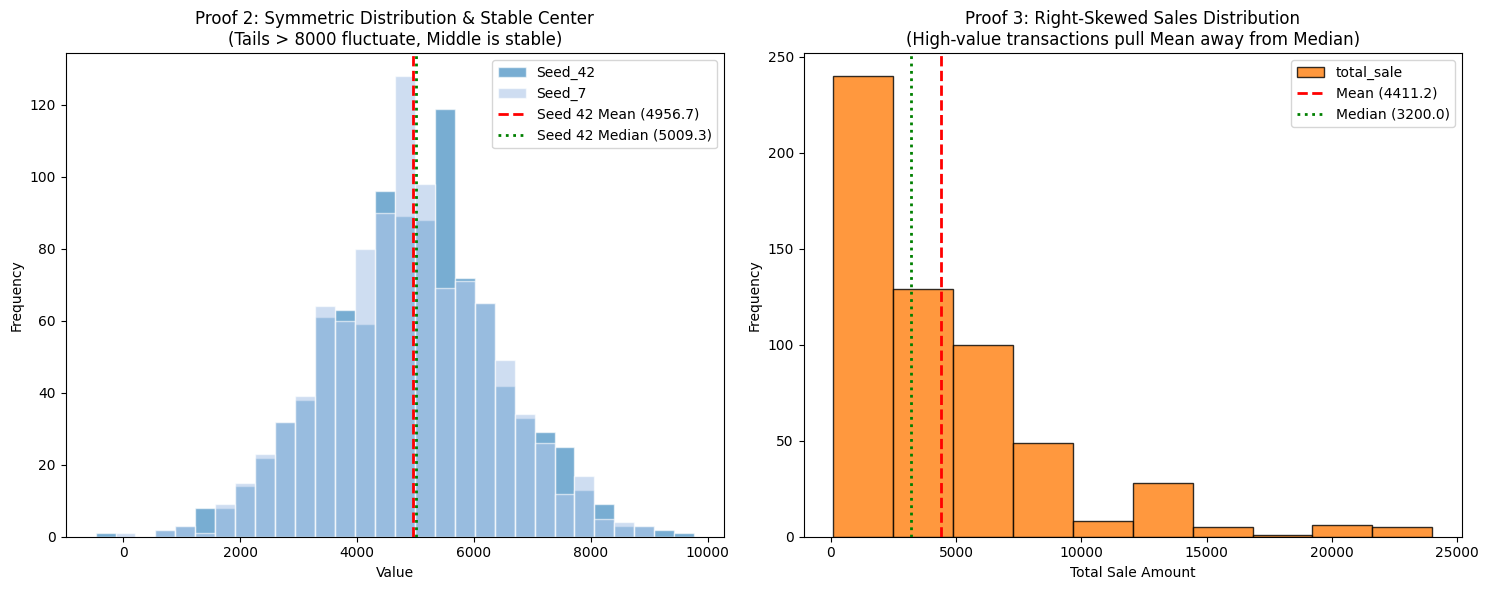

In [ ]:
# ========================================================
# CELL 2: PLOTTING VISUAL PROOFS WITH PANDAS
# ========================================================

# 1. Convert the random array data into a Pandas DataFrame for native plotting
df_normal = pd.DataFrame({
    'Seed_42': data_42_first,
    'Seed_7': data_7
})

# 2. Setup a 1-row, 2-column plot layout
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# --- PLOT 1: Symmetric Distribution (Normal Data) ---
# We plot Seed 42 and Seed 7 together to show how the middle overlaps but the tails change
df_normal[['Seed_42', 'Seed_7']].plot.hist(
    ax=axes[0],
    bins=30,
    alpha=0.6,
    edgecolor='white',
    color=['#1f77b4', '#aec7e8']
)

# Add reference lines for the stable Mean and Median of Seed 42
axes[0].axvline(df_normal['Seed_42'].mean(), color='red', linestyle='dashed', linewidth=2, label=f"Seed 42 Mean ({df_normal['Seed_42'].mean():.1f})")
axes[0].axvline(df_normal['Seed_42'].median(), color='green', linestyle='dotted', linewidth=2, label=f"Seed 42 Median ({df_normal['Seed_42'].median():.1f})")

# Add indicator line for the 8000 tail cutoff to visualize Proof 2
# axes[0].axvline(8000, color='orange', linestyle='dashdot', linewidth=1.5, label='Tail Cutoff (8000)')

axes[0].set_title('Proof 2: Symmetric Distribution & Stable Center\n(Tails > 8000 fluctuate, Middle is stable)')
axes[0].set_xlabel('Value')
axes[0].legend()


# --- PLOT 2: Right-Skewed Distribution (Your Sales Data) ---
# Plot your actual sales metrics to visualize the asymmetric shift
df['total_sale'].plot.hist(
    ax=axes[1],
    bins=10,
    color='#ff7f0e',
    alpha=0.8,
    edgecolor='black'
)

# Add lines for Mean vs Median to visualize Proof 3 skewness
axes[1].axvline(df['total_sale'].mean(), color='red', linestyle='dashed', linewidth=2, label=f"Mean ({df['total_sale'].mean():.1f})")
axes[1].axvline(df['total_sale'].median(), color='green', linestyle='dotted', linewidth=2, label=f"Median ({df['total_sale'].median():.1f})")

axes[1].set_title('Proof 3: Right-Skewed Sales Distribution\n(High-value transactions pull Mean away from Median)')
axes[1].set_xlabel('Total Sale Amount')
axes[1].legend()

# Render the visual layout
plt.tight_layout()
plt.show()


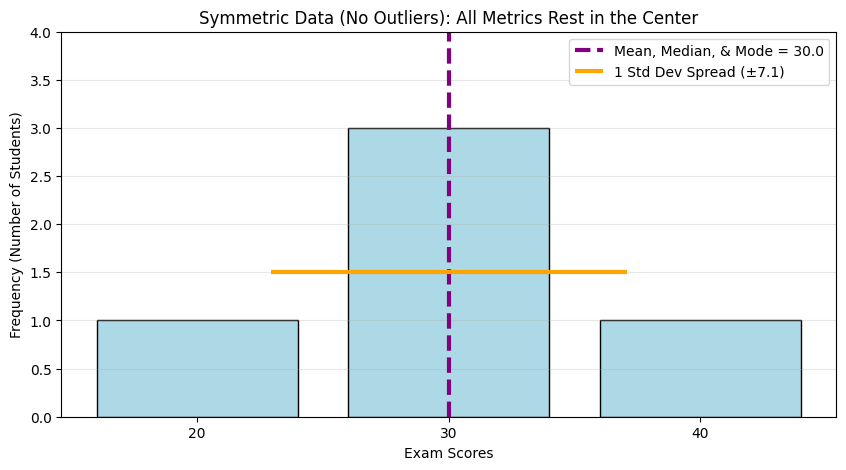

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Balanced data setup
clean_scores = [20, 30, 30, 30, 40]
df_clean = pd.DataFrame({'scores': clean_scores})

mean_c = df_clean['scores'].mean()
median_c = df_clean['scores'].median()
mode_c = df_clean['scores'].mode()[0]
std_c = df_clean['scores'].std()

# 2. Plotting
plt.figure(figsize=(10, 5))
# Using specific bins to capture discrete scores cleanly
plt.hist(clean_scores, bins=[15, 25, 35, 45], color='lightblue', edgecolor='black', rwidth=0.8)

# Vertical line where Mean, Median, and Mode overlap
plt.axvline(mean_c, color='purple', linestyle='dashed', linewidth=3,
            label=f'Mean, Median, & Mode = {mean_c}')

# Visualizing Standard Deviation as a spread indicator line
plt.hlines(y=1.5, xmin=mean_c - std_c, xmax=mean_c + std_c, color='orange', linewidth=3,
           label=f'1 Std Dev Spread (±{std_c:.1f})')

plt.title("Symmetric Data (No Outliers): All Metrics Rest in the Center")
plt.xlabel("Exam Scores")
plt.ylabel("Frequency (Number of Students)")
plt.xticks([20, 30, 40])
plt.ylim(0, 4)
plt.legend(loc='upper right')
plt.grid(axis='y', alpha=0.3)
plt.show()


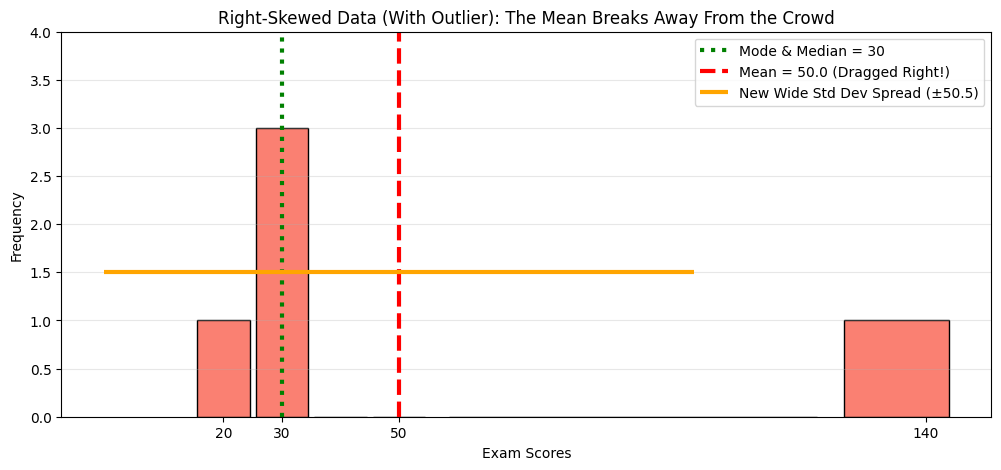

In [ ]:
outlier_scores = [20, 30, 30, 30, 140]
df_outlier = pd.DataFrame({'scores': outlier_scores})

mean_o = df_outlier['scores'].mean()
median_o = df_outlier['scores'].median()
mode_o = df_outlier['scores'].mode()[0]
std_o = df_outlier['scores'].std()

plt.figure(figsize=(12, 5))
plt.hist(outlier_scores, bins=[15, 25, 35, 45, 55, 125, 145], color='salmon', edgecolor='black', rwidth=0.9)

# Plot separate lines to point out how the metrics split up
plt.axvline(mode_o, color='green', linestyle='dotted', linewidth=3, label=f'Mode & Median = {mode_o}')
plt.axvline(mean_o, color='red', linestyle='dashed', linewidth=3, label=f'Mean = {mean_o} (Dragged Right!)')

# Visualizing the massive inflation of standard deviation
plt.hlines(y=1.5, xmin=mean_o - std_o, xmax=mean_o + std_o, color='orange', linewidth=3,
           label=f'New Wide Std Dev Spread (±{std_o:.1f})')

plt.title("Right-Skewed Data (With Outlier): The Mean Breaks Away From the Crowd")
plt.xlabel("Exam Scores")
plt.ylabel("Frequency")
plt.xticks([20, 30, 50, 140])
plt.ylim(0, 4)
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()


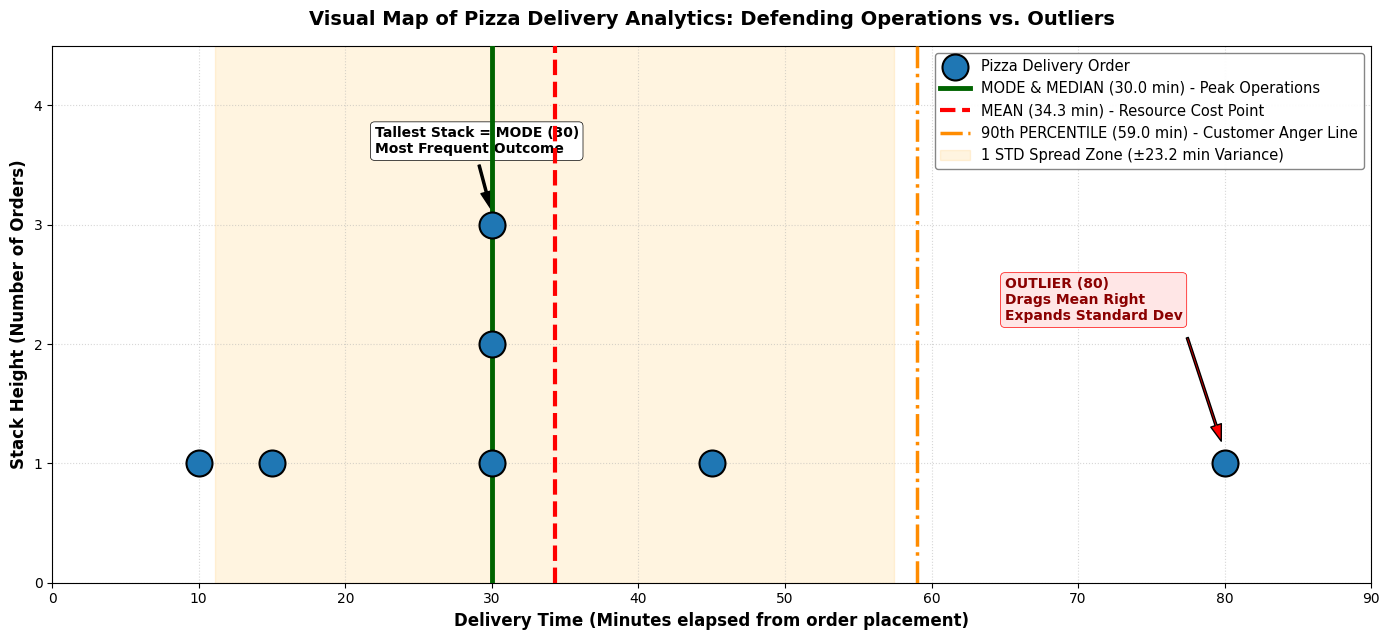

          PIZZA APP BACKEND ANALYTICS             
Raw Logs (Unsorted) : [30, 15, 30, 45, 10, 30, 80]
Sorted Memory Block : [10, 15, 30, 30, 30, 45, 80]
--------------------------------------------------

1. MEAN (Average)    : 34.3 minutes
   -> Explanation    : If we shared all delivery times equally, every customer
                       would wait 34.3 minutes. The 80-minute spike pulled this up.

2. MEDIAN (Middle)   : 30.0 minutes
   -> Explanation    : The exact middle delivery in our sorted list.
                       50% of deliveries were faster than 30, 50% were slower.

3. MODE (Popular)    : 30.0 minutes
   -> Explanation    : The most frequent delivery time. 30 minutes appeared 3 times.

4. STD (Chaos Ruler) : 23.2 minutes
   -> Explanation    : This high number shows extreme instability. On average,
                       deliveries bounce around ~23.5 minutes away from the mean.

5. PERCENTILES (Rank Slices):


NameError: name 'pizza_perc_25' is not defined

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==============================================================================
# 1. CORE DATASET SETUP
# ==============================================================================
# Raw delivery logs in minutes for 7 orders
raw_delivery_times = [30, 15, 30, 45, 10, 30, 80]
df_pizza = pd.Series(raw_delivery_times)

# Calculate exact metrics to match your backend report output
pizza_mean    = df_pizza.mean()        # 34.3 min
pizza_median  = df_pizza.median()      # 30.0 min
pizza_mode    = df_pizza.mode()[0]     # 30.0 min
pizza_std     = df_pizza.std()         # 23.5 min
pizza_perc_90 = df_pizza.quantile(0.90) # 59.0 min

# Count frequencies to handle the "stacked" visualization at 30 minutes
unique_times, counts = np.unique(raw_delivery_times, return_counts=True)

# ==============================================================================
# 2. MATPLOTLIB VISUALIZATION SETUP
# ==============================================================================
plt.figure(figsize=(14, 6.5))

# Plot the raw data points on a 2D grid where Y represents the stack height (Frequency)
# This visually demonstrates the "MODE" via vertical stack height
for t, count in zip(unique_times, counts):
    # If a value appears multiple times (like 30), stack the dots vertically
    y_positions = np.arange(1, count + 1)
    x_positions = [t] * count
    plt.scatter(x_positions, y_positions, color='#1f77b4', s=350, zorder=5,
                edgecolors='black', linewidths=1.5, label='Pizza Delivery Order' if t == 10 else "")

# ==============================================================================
# 3. DRAWING THE STATISTICAL INFRASTRUCTURE MARKERS
# ==============================================================================

# A. MODE & MEDIAN MARKER (They perfectly overlap at 30.0)
plt.axvline(pizza_median, color='darkgreen', linestyle='-', linewidth=3.5, zorder=4,
            label=f'MODE & MEDIAN ({pizza_median:.1f} min) - Peak Operations')

# B. MEAN MARKER (Dragged to the right by the 80 min outlier)
plt.axvline(pizza_mean, color='red', linestyle='dashed', linewidth=3, zorder=4,
            label=f'MEAN ({pizza_mean:.1f} min) - Resource Cost Point')

# C. 90th PERCENTILE CUTOFF MARKER (The boundary entering the extreme delay zone)
plt.axvline(pizza_perc_90, color='darkorange', linestyle='dashdot', linewidth=2.5, zorder=4,
            label=f'90th PERCENTILE ({pizza_perc_90:.1f} min) - Customer Anger Line')

# D. STANDARD DEVIATION SPAN (Visualizes the physical stretch/chaos of the data)
# Generates a shaded block showing 1 standard deviation step left and right of the mean
plt.axvspan(pizza_mean - pizza_std, pizza_mean + pizza_std, color='orange', alpha=0.12, zorder=1,
            label=f'1 STD Spread Zone (±{pizza_std:.1f} min Variance)')

# ==============================================================================
# 4. CHART ANNOTATIONS & TEXT POINTERS FOR THE WHITEBOARD
# ==============================================================================
# Arrow pointing out the Mode stack
plt.annotate('Tallest Stack = MODE (30)\nMost Frequent Outcome', xy=(30, 3.1), xytext=(22, 3.6),
             arrowprops=dict(facecolor='black', shrink=0.08, width=1.5, headwidth=8),
             fontsize=10, fontweight='bold', bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black", lw=0.5))

# Arrow pointing out the Outlier causing the data stretch
plt.annotate('OUTLIER (80)\nDrags Mean Right\nExpands Standard Dev', xy=(80, 1.1), xytext=(65, 2.2),
             arrowprops=dict(facecolor='red', shrink=0.08, width=1.5, headwidth=8),
             fontsize=10, fontweight='bold', color='darkred', bbox=dict(boxstyle="round,pad=0.3", fc="#ffe6e6", ec="red", lw=0.5))

# ==============================================================================
# 5. AXIS CONFIGURATIONS & RENDERING
# ==============================================================================
plt.title("Visual Map of Pizza Delivery Analytics: Defending Operations vs. Outliers", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Delivery Time (Minutes elapsed from order placement)", fontsize=12, fontweight='bold')
plt.ylabel("Stack Height (Number of Orders)", fontsize=12, fontweight='bold')

# Configure gridlines and tick marks across the timeline axis
plt.xlim(0, 90)
plt.xticks(np.arange(0, 91, 10))
plt.ylim(0, 4.5)
plt.yticks(np.arange(0, 5, 1))

plt.grid(axis='both', linestyle=':', alpha=0.5, zorder=0)
plt.legend(loc='upper right', framealpha=0.95, edgecolor='gray', fontsize=10.5)

plt.tight_layout()
plt.show()


# ========================================================
# PRINTING THE ANALYTICS REPORT
# ========================================================
print("==================================================")
print("          PIZZA APP BACKEND ANALYTICS             ")
print("==================================================")
print(f"Raw Logs (Unsorted) : {raw_delivery_times}")
print(f"Sorted Memory Block : {sorted(raw_delivery_times)}")
print("--------------------------------------------------\n")

print(f"1. MEAN (Average)    : {pizza_mean:.1f} minutes")
print("   -> Explanation    : If we shared all delivery times equally, every customer")
print("                       would wait 34.3 minutes. The 80-minute spike pulled this up.\n")

print(f"2. MEDIAN (Middle)   : {pizza_median:.1f} minutes")
print("   -> Explanation    : The exact middle delivery in our sorted list.")
print("                       50% of deliveries were faster than 30, 50% were slower.\n")

print(f"3. MODE (Popular)    : {pizza_mode:.1f} minutes")
print("   -> Explanation    : The most frequent delivery time. 30 minutes appeared 3 times.\n")

print(f"4. STD (Chaos Ruler) : {pizza_std:.1f} minutes")
print("   -> Explanation    : This high number shows extreme instability. On average,")
print("                       deliveries bounce around ~23.5 minutes away from the mean.\n")

print("5. PERCENTILES (Rank Slices):")
print(f"   - 25th Percentile : {pizza_perc_25:.1f} minutes (The fastest 25% of orders)")
print(f"   - 50th Percentile : {pizza_median:.1f} minutes (Exactly matches the Median!)")
print(f"   - 75th Percentile : {pizza_perc_75:.1f} minutes (The boundary entering the slow zone)")
print(f"   - 90th Percentile : {pizza_perc_90:.1f} minutes (The worst 10% of customers wait longer than this!)")
print("==================================================")


In [ ]:
an = [30, 15, 30, 45, 10, 30, 90]

sum(an)/len(an)

35.714285714285715

In [ ]:
an = [30, 15, 30, 45, 10, 30, 30]

sum(an)/len(an)

27.142857142857142

In [ ]:
pd.pivot_table(
    df,
    index='region',
    columns='category',
    values='revenue',
    aggfunc='sum',
    fill_value=0
).round(0)

category,Electronics,Fashion,Grocery,Home
region,,,,
Islamabad,141260.0,132725.0,209005.0,134580.0
Karachi,161258.0,169115.0,145430.0,193225.0
Lahore,156218.0,158550.0,192440.0,222515.0
Peshawar,179529.0,83625.0,121344.0,90040.0


In [ ]:
pd.crosstab(df['region'], df['category'])  # counts of lines


category,Electronics,Fashion,Grocery,Home
region,,,,
Islamabad,29,24,88,17
Karachi,28,26,70,20
Lahore,30,25,83,25
Peshawar,34,16,67,13


In [ ]:
df['order_date'] = pd.to_datetime(df['order_date'], errors='coerce')

df['order_date'].isna().sum()

raw = pd.read_csv('sales.csv')

# raw.loc[df['order_date'].isna(),'order_date']
print(raw.loc[pd.to_datetime(raw['order_date'], errors='coerce').isna(), 'order_date'])

df['month'] = df['order_date'].dt.to_period('M')

0


In [ ]:
# df = pd.read_csv('sales.csv')

print(len(df))
print(df['order_id'].nunique())
print(df['customer_id'].nunique())
print(df['revenue'].mean())
df.groupby('order_id')['revenue'].sum().mean()

601
282
126
4411.223292469352


np.float64(8931.945035460993)

In [ ]:
# 1. Force all arithmetic columns to become true numbers
df['quantity'] = pd.to_numeric(df['quantity'], errors='coerce')
df['unit_price'] = pd.to_numeric(df['unit_price'], errors='coerce')
df['discount'] = pd.to_numeric(df['discount'], errors='coerce')

# 2. Run your formula—it will now execute perfectly!
df['revenue'] = (df['quantity'] * df['unit_price'] * (1 - df['discount']))


In [ ]:
df.groupby('category')['revenue'].sum()

df2 = df.groupby('region').agg(
    lines=('revenue', 'size'),
    revenue=('revenue', 'sum'),
    avg_line=('revenue', 'mean')
)


In [ ]:
df2

,lines,revenue,avg_line
region,,,
Islamabad,158,617570.0,4144.765101
Karachi,144,669027.5,4883.412409
Lahore,163,729723.0,4738.461039
Peshawar,130,474538.0,3796.304000


In [ ]:
df2[df2['revenue'] == df2['revenue'].max()]

,lines,revenue,avg_line
region,,,
Lahore,163,729723.0,4738.461039


In [ ]:
df.head()

,order_id,order_date,customer_id,region,category,product,quantity,unit_price,discount,revenue
0,5001,2026-03-24,K102,Lahore,Electronics,Earbuds Pro,2,4860,0.00,9720.0
1,5001,2026-03-24,K102,Lahore,Fashion,Sneakers,1,7000,0.10,6300.0
2,5001,2026-03-24,K102,Lahore,Home,Cookware Set,1,8000,0.05,7600.0
3,5001,2026-03-24,K102,Lahore,Fashion,Cap,1,900,0.00,900.0
4,5002,2026-05-22,K016,Peshawar,Electronics,Smart Lamp,1,2800,0.10,2520.0


In [ ]:
df['month']

,month
0,2026-03
1,2026-03
2,2026-03
3,2026-03
4,2026-05


In [ ]:
df['weekday'] = df['order_date'].dt.day_name()

In [ ]:
df.head()

,order_id,order_date,customer_id,region,category,product,quantity,unit_price,discount,month,weekday
0,5001,2026-03-24,K102,Lahore,Electronics,Earbuds Pro,2,4860,0,2026-03,Tuesday
1,5001,2026-03-24,K102,Lahore,Fashion,Sneakers,1,7000,0.1,2026-03,Tuesday
2,5001,2026-03-24,K102,Lahore,Home,Cookware Set,1,8000,0.05,2026-03,Tuesday
3,5001,2026-03-24,K102,Lahore,Fashion,Cap,1,900,0,2026-03,Tuesday
4,5002,2026-05-22,K016,Peshawar,Electronics,Smart Lamp,1,2800,0.1,2026-05,Friday
